# Danish 1.3 corner and FAM collections: dataset types and contents (v1)

**Author:** Aaron Roodman (prepared by Claude)  
**Date Created:** 2026-10-24  
**Last Modified:** 2026-10-24  
**Status:** In Progress  
**Keywords:** CWFS, FAM, Danish 1.3, blitz, unpaired, donutBlitzCornerResults, Butler  

## Description

Explores the Danish 1.3 blitz unpaired collections before they become `cwfs_tables` and
`fam_tables` variants: the science corner wavefront sensor (CWFS) run (RSO-1071) and Josh
Meyers' v3.14 pupil-model FAM and corner runs.

1. Which dataset types each collection holds, and its child runs.
2. Night and visit coverage of the results dataset type.
3. One `donutBlitzCornerResults` table: columns, units, metadata, the Zernike vectors.
4. Intra/extra side from `defocal_offsets`, and the corner sensors present.

**Output:** printed tables and one figure, inline only  
**References:** `rubinwork/products/fam_tables/builders/blitz_reader.py` (the FAM reader of
the same blitz layout); RSO-1071

## Parameters

In [1]:
BUTLER_REPO = '/repo/main'
SCIENCE_CWFS = ('LSSTCam/runs/aos/cwfs/danish_1_3_0/wep_blitz_rso1071/dv_blitz_rso1071/'
                'bin_x2/unpaired/donutBlitz')
JOSH = {g: f'u/jmeyers3/{g}_v3.14' for g in
        ('t614_fam_unpaired', 'sensitivity_fam_unpaired',
         't614_corner_unpaired', 'sensitivity_corner_unpaired', 'bounce_corner_unpaired')}
RESULT_TYPES = ('donutBlitzCornerResults', 'donutBlitzFamResults')
SKIP_SUFFIXES = ('_config', '_log', '_metadata')

## Setup & Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lsst.daf.butler import Butler

butler = Butler(BUTLER_REPO)

## 1. Dataset types and child runs

Output dataset types only; calibrations, reference catalogs and `raw` are dropped.

In [3]:
INPUTS = {'raw', 'camera', 'skyMap', 'packages'}
def summary(collection):
    info = butler.collections.query_info(collection, include_summary=True, include_chains=True)[0]
    types = sorted(t for t in (info.dataset_types or [])
                   if not t.endswith(SKIP_SUFFIXES) and t not in INPUTS
                   and ('Blitz' in t or 'zernike' in t.lower() or 'aggregate' in t.lower()
                        or 'intrinsic' in t.lower()))
    return info, types

rows = []
for label, coll in {'science_cwfs': SCIENCE_CWFS, **JOSH}.items():
    info, types = summary(coll)
    rows.append((label, info.type.name, len(info.children or []), ', '.join(types)))
pd.set_option('display.max_colwidth', 200)
pd.DataFrame(rows, columns=['collection', 'type', 'children [count]', 'output dataset types'])

,collection,type,children [count],output dataset types
0,science_cwfs,CHAINED,10,"aggregateAOSVisitTableAvg, aggregateAOSVisitTableRaw, donutBlitzCornerResults, zernikes"
1,t614_fam_unpaired,CHAINED,195,"donutBlitzFamResults, intrinsicZernikes"
2,sensitivity_fam_unpaired,CHAINED,195,"donutBlitzFamResults, intrinsicZernikes"
3,t614_corner_unpaired,CHAINED,195,"donutBlitzCornerResults, intrinsicZernikes"
4,sensitivity_corner_unpaired,CHAINED,195,"donutBlitzCornerResults, intrinsicZernikes"
5,bounce_corner_unpaired,CHAINED,196,"donutBlitzCornerResults, intrinsicZernikes"


In [4]:
info, _ = summary(SCIENCE_CWFS)
print(f'{SCIENCE_CWFS}: {len(info.children)} child runs (count)')
for ch in info.children:
    print('  ', ch.split('/donutBlitz/')[-1])

LSSTCam/runs/aos/cwfs/danish_1_3_0/wep_blitz_rso1071/dv_blitz_rso1071/bin_x2/unpaired/donutBlitz: 10 child runs (count)
   all/20251020_20251126/20261012T234353Z
   all/20251127_20260103/20261013T022529Z
   all/20260104_20260223/20261013T022539Z
   all/20260224_20260311/20261013T023321Z
   all/20260312_20260330/20261013T023343Z
   all/20260331_20260414/20261013T041748Z
   all/20260415_20260511/20261013T041755Z
   all/20260512_20260528/20261013T041805Z
   all/20260529_20260626/20261013T192138Z
   all/20260627_20260714/20261013T050136Z


## 2. Coverage of the results dataset type

Visits and nights per collection. The Josh corner and FAM chains include the inputs, so only the results type is counted.

In [5]:
def coverage(collection):
    for dt in RESULT_TYPES:
        if dt not in (summary(collection)[0].dataset_types or []):
            continue
        with butler.query() as q:
            refs = list(q.datasets(dt, collections=collection))
        nights = sorted({r.dataId['day_obs'] for r in refs})
        return dt, len(refs), nights
    return None, 0, []

cov = {}
for label, coll in {'science_cwfs': SCIENCE_CWFS, **JOSH}.items():
    dt, n, nights = coverage(coll)
    cov[label] = nights
    print(f'{label:28s} {dt}: {n} visits over {len(nights)} nights (counts), '
          f'{nights[0] if nights else "-"} to {nights[-1] if nights else "-"}')

science_cwfs                 donutBlitzCornerResults: 92392 visits over 191 nights (counts), 20251021 to 20260714
t614_fam_unpaired            donutBlitzFamResults: 966 visits over 15 nights (counts), 20260315 to 20260619


sensitivity_fam_unpaired     donutBlitzFamResults: 912 visits over 31 nights (counts), 20250417 to 20260522


t614_corner_unpaired         donutBlitzCornerResults: 964 visits over 15 nights (counts), 20260315 to 20260619
sensitivity_corner_unpaired  donutBlitzCornerResults: 989 visits over 31 nights (counts), 20250417 to 20260522


bounce_corner_unpaired       donutBlitzCornerResults: 168 visits over 7 nights (counts), 20260418 to 20260713


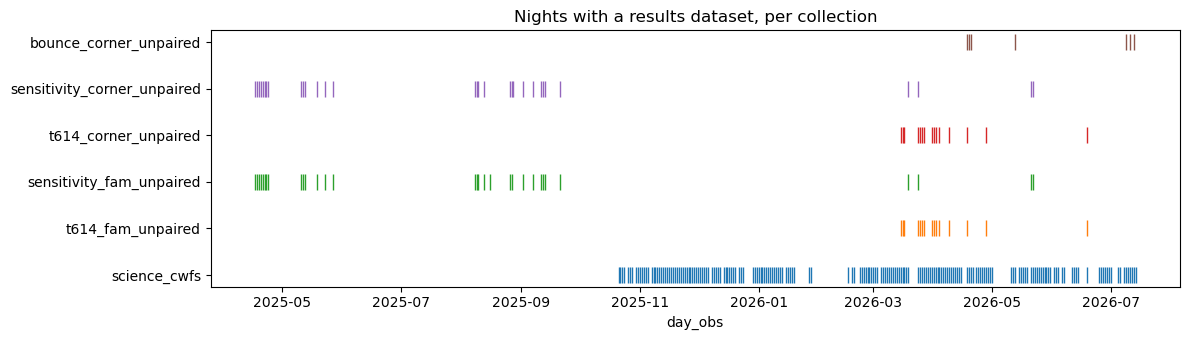

In [6]:
fig, ax = plt.subplots(figsize=(12, 3.5))
for i, (label, nights) in enumerate(cov.items()):
    d = pd.to_datetime([str(n) for n in nights])
    ax.plot(d, np.full(len(d), i), '|', ms=12)
ax.set_yticks(range(len(cov)), list(cov))
ax.set_xlabel('day_obs')
ax.set_title('Nights with a results dataset, per collection')
plt.tight_layout()

## 3. One `donutBlitzCornerResults` table

In [7]:
with butler.query() as q:
    ref = list(q.datasets('donutBlitzCornerResults', collections=SCIENCE_CWFS).limit(1))[0]
print(ref.dataId)
tab = butler.get(ref)
print(f'{len(tab)} rows (count, one per donut)')
cols = pd.DataFrame([(c, str(tab[c].dtype), tab[c].shape[1:] if tab[c].ndim > 1 else '',
                      str(getattr(tab[c], 'unit', '') or ''))
                     for c in tab.colnames], columns=['column', 'dtype', 'shape', 'unit'])
cols

{instrument: 'LSSTCam', visit: 2025102100094, band: 'z', day_obs: 20251021, physical_filter: 'z_20'}


58 rows (count, one per donut)


,column,dtype,shape,unit
0,visit_id,int64,,
1,det_id,int64,,
2,det_name,<U7,,
3,donut_id,int64,,
4,band,<U1,,
...,...,...,...,...
57,zk_intrinsic_eb,float64,"(67,)",micron
58,thx_ocs,float64,,rad
59,thy_ocs,float64,,rad
60,zk_deviation_ocs,float64,"(27,)",micron


In [8]:
for k, v in tab.meta.items():
    s = repr(v)
    print(f'{k}: {s[:160]}')

### The Zernike vectors

The FAM reader expects `zk_deviation_*` with Noll `j` at index `j` and selects the `noll_indices` from the metadata. Check that here.

In [9]:
zk_cols = [c for c in tab.colnames if c.startswith('zk')]
for c in zk_cols:
    a = np.asarray(tab[c])
    print(f'{c}: shape {a.shape}; all-zero entries at index '
          f'{[j for j in range(a.shape[1]) if np.all(a[:, j] == 0)]}; all-NaN at '
          f'{[j for j in range(a.shape[1]) if np.all(np.isnan(a[:, j]))]}')
print('noll_indices in meta:', tab.meta.get('noll_indices'))

zk_deviation_ccs: shape (58, 27); all-zero entries at index []; all-NaN at [20, 21]
zk_intrinsic_ccs: shape (58, 67); all-zero entries at index [0, 1, 2, 3]; all-NaN at []
zk_deviation_eb: shape (58, 27); all-zero entries at index []; all-NaN at [20, 21]
zk_intrinsic_eb: shape (58, 67); all-zero entries at index [0, 1, 2, 3]; all-NaN at []
zk_deviation_ocs: shape (58, 27); all-zero entries at index []; all-NaN at [20, 21]
zk_intrinsic_ocs: shape (58, 67); all-zero entries at index [0, 1, 2, 3]; all-NaN at []
noll_indices in meta: None


### Metadata, and the size of the deviations

The metadata (`noll_indices` and the rest) is only kept with
`parameters={'strip_astropy_meta_yaml': False}`, as `blitz_reader` reads it. Then the
per-donut deviation in OCS (µm of wavefront), by Noll index, over this visit, and how many
donuts (count) carry a nonzero Noll 0-3 entry or a fit that did not succeed.

In [10]:
tab = butler.get(ref, parameters={'strip_astropy_meta_yaml': False})
for k, v in tab.meta.items():
    print(f'{k}: {repr(v)[:160]}')
dev = np.asarray(tab['zk_deviation_ocs'], float)
noll = [int(j) for j in tab.meta.get('noll_indices', range(4, 27))]
stats = pd.DataFrame({'median [um]': np.nanmedian(dev[:, noll], axis=0),
                      'nMAD [um]': 1.4826 * np.nanmedian(np.abs(dev[:, noll] - np.nanmedian(dev[:, noll], axis=0)), axis=0),
                      'max |.| [um]': np.nanmax(np.abs(dev[:, noll]), axis=0)}, index=[f'Z{j}' for j in noll])
print(f'donuts with a nonzero Noll 0-3 entry: {int((dev[:, :4] != 0).any(axis=1).sum())} of {len(dev)} (count)')
print('group_fit_success:', dict(zip(*np.unique(np.asarray(tab['group_fit_success']), return_counts=True))))
print('group_fit_outcome:', dict(zip(*np.unique(np.asarray(tab['group_fit_outcome']).astype(str), return_counts=True))))
stats.round(3).T

ref_visit_id: 2025102100094
intra_visit_id: 2025102100094
extra_visit_id: 2025102100094
exposure_group: '2025-10-22T03:43:37.317'
mode: 'corner'
run_elapsed: <Quantity 13.47319884 s>
refcat_elapsed: <Quantity 0.18342986 s>
butler_elapsed: <Quantity 14.29421903 s>
butler_times: {'crosstalk': <Quantity 0.41651262 s>, 'flat': <Quantity 3.27672149 s>, 'intrinsicZernikes': <Quantity 1.1998579 s>, 'linearizer': <Quantity 1.48895115 s>, 'ptc
cutout_elapsed: <Quantity 5.07905042 s>
danish_elapsed: <Quantity 8.11830386 s>
photo_filter_name: 'phot_rp_mean'
astrom_filter_name: 'phot_rp_mean'
noll_indices: [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 22, 23, 24, 25, 26]
binning: 2
stamp_frame: 'CCS'
stamp_size: 167
max_nearby: 5
offset_optics: ['Detector', 'LSSTCamera', 'M2']
zk_deviation_jmax: 26
zk_intrinsic_jmax: 66
rot_tel_pos: <Quantity -15.97096779 deg>
instrument: 'LSSTCam'
date: <Time object: scale='tai' format='mjd' value=60970.155445376>
exposure_time: <Quantity 15.00005651

,Z4,Z5,Z6,Z7,Z8,Z9,Z10,Z11,Z12,Z13,...,Z15,Z16,Z17,Z18,Z19,Z22,Z23,Z24,Z25,Z26
median [um],1.404,0.000,2.402,0.104,-0.256,-0.165,0.598,0.141,-0.074,0.000,...,0.384,0.006,0.000,0.028,0.048,0.000,-0.009,0.031,0.000,0.096
nMAD [um],2.167,7.213,4.705,0.705,1.132,2.960,3.704,0.327,0.529,0.638,...,1.800,0.153,0.153,0.266,0.330,0.083,0.134,0.109,0.341,0.261
max |.| [um],36.797,216.495,244.320,60.857,55.187,69.106,66.296,2.893,36.619,40.852,...,49.211,14.592,12.481,6.184,17.432,5.149,11.280,4.585,6.399,10.789


## 4. Sides and sensors

`defocal_offsets` is a 3-vector per donut; negative is intra-focal. On the corner rafts SW1 should be intra and SW0 extra.

In [11]:
off = np.asarray(tab['defocal_offsets'], float)
vary = [k for k in range(off.shape[1]) if np.ptp(off[:, k]) > 0]
print('varying defocal_offsets element(s):', vary)
side = np.where(off[:, vary[0]] < 0, 'intra', 'extra') if vary else np.full(len(tab), '?')
pd.crosstab(np.asarray(tab['det_name']).astype(str), side)

varying defocal_offsets element(s): [0]


col_0,extra,intra
row_0,,
R00_SW0,16,0
R04_SW0,8,0
R40_SW0,8,0
R40_SW1,0,10
R44_SW0,5,0
R44_SW1,0,11


Text(0.5, 1.0, 'Donut field angles, visit 2025102100094')

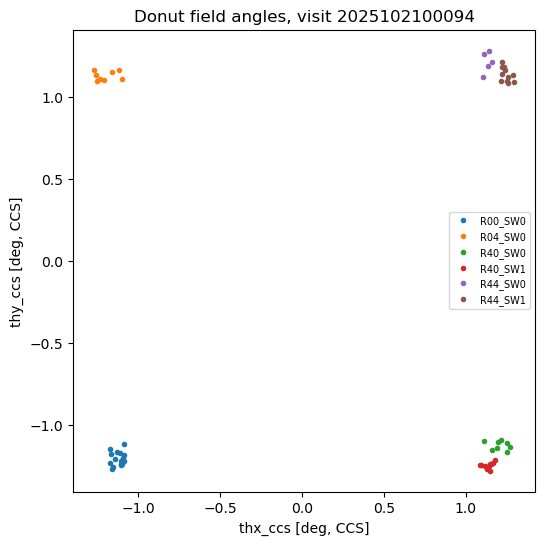

In [12]:
det = np.asarray(tab['det_name']).astype(str)
fig, ax = plt.subplots(figsize=(6, 6))
for d in sorted(set(det)):
    m = det == d
    ax.plot(np.degrees(np.asarray(tab['thx_ccs'])[m]), np.degrees(np.asarray(tab['thy_ccs'])[m]),
            '.', label=d)
ax.set_aspect('equal'); ax.legend(fontsize=7)
ax.set_xlabel('thx_ccs [deg, CCS]'); ax.set_ylabel('thy_ccs [deg, CCS]')
ax.set_title(f'Donut field angles, visit {ref.dataId["visit"]}')

## Findings

- **The science CWFS results type is `donutBlitzCornerResults`**, one table per visit, the
  same blitz layout as the FAM's `donutBlitzFamResults` plus three per-donut image columns
  (`stamp`, `wf_img`, `model_img`). The collection also carries `aggregateAOSVisitTableAvg`,
  `aggregateAOSVisitTableRaw` and per-detector `zernikes`.
- **Coverage (counts):** science CWFS 92,392 visits over 191 nights, 20251021-20260714, in
  10 child runs. Josh's v3.14: `t614_fam_unpaired` 966 visits over 15 nights,
  `sensitivity_fam_unpaired` 912 over 31, `t614_corner_unpaired` 964 over 15,
  `sensitivity_corner_unpaired` 989 over 31, `bounce_corner_unpaired` 168 over 7. No FAM
  bounce run, as Josh said.
- **Metadata** needs `strip_astropy_meta_yaml=False`. It carries `noll_indices` (the same
  21 as Danish 1.2), `wf_mode: unpaired`, `mask_model: RubinObsc_v3.14_...`,
  `danish_version: 1.3.0`, `rot_tel_pos` and `ts_wep_version: '?'`.
- **Zernike vectors** are 0-indexed on Noll, as in the FAM: `zk_deviation_*` 27 entries,
  NaN at Noll 20-21; `zk_intrinsic_*` 67. Frames `ccs`, `ocs` and `eb`.
- **Failed fits must be dropped.** In this visit 35 of 58 donuts (count) have
  `group_fit_success` False and an empty `group_fit_outcome`; their deviations are junk,
  up to 244 µm of wavefront, and only they carry nonzero Noll 0-3 entries.
- **Sides:** `defocal_offsets` element 0 varies; negative is intra. All SW1 donuts are
  intra and all SW0 donuts extra, as expected. Some visits lack a corner half (here no
  R00_SW1 or R04_SW1).

So the `cwfs_tables` builder needs a blitz-corner reader: `blitz_reader`'s FAM path with
the image columns dropped, the failed fits cut, and the per-donut `wfs_offset` from
`defocal_offsets`.